# Le poids des mines dans l'économie guinéenne (2000-2025)

**Question :** à quel point l'économie de la Guinée dépend-elle des mines, comment cela a-t-il évolué, et la Guinée est-elle plus dépendante que ses voisins ?

**Sources :**
- Banque mondiale (API), 2000-2025 : rente minière en % du PIB, part des minerais et métaux dans les exportations, PIB. Script : `src/telecharger_banque_mondiale.py`. Les graphiques sont dans `src/graphiques.py`.
- Sources nationales guinéennes, 2019-2025 (`data/sources_nationales.csv`) : Ministère des Mines et de la Géologie (Annuaire statistique 2023, Bulletin annuel 2024), INS (commerce extérieur 2024), presse pour 2025. Source et page indiquées pour chaque chiffre.

Pays de comparaison : Sierra Leone, Mali, Côte d'Ivoire, Sénégal.

In [1]:
import sys
sys.path.append("..")          # pour trouver le dossier src/ depuis notebooks/

import duckdb
from src.graphiques import graphique_rente, graphique_exportations, graphique_bauxite

RENTE = "'../data/rente_miniere.csv'"
EXPORT = "'../data/export_minerais.csv'"
PIB = "'../data/pib.csv'"
NAT = "'../data/sources_nationales.csv'"

## 1. La Guinée face à ses voisins : la rente minière (Banque mondiale)

In [2]:
duckdb.sql(f"""
    SELECT pays,
           ROUND(AVG(valeur), 1) AS rente_moyenne_2000_2018,
           ROUND(MAX(valeur), 1) AS rente_max
    FROM {RENTE}
    WHERE annee BETWEEN 2000 AND 2018
    GROUP BY pays
    ORDER BY rente_moyenne_2000_2018 DESC
""").show()

┌───────────────┬─────────────────────────┬───────────┐
│     pays      │ rente_moyenne_2000_2018 │ rente_max │
│    varchar    │         double          │  double   │
├───────────────┼─────────────────────────┼───────────┤
│ Guinea        │                     6.0 │       9.8 │
│ Mali          │                     4.1 │       9.1 │
│ Sierra Leone  │                     0.8 │       3.7 │
│ Senegal       │                     0.7 │       2.4 │
│ Cote d'Ivoire │                     0.2 │       0.7 │
└───────────────┴─────────────────────────┴───────────┘



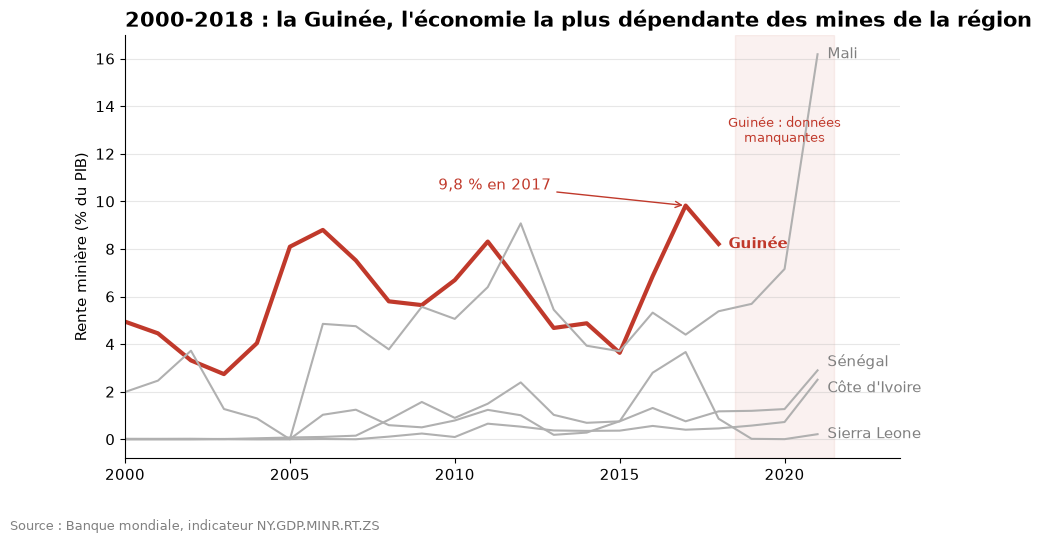

In [3]:
# Les 0 de la Guinée en 2019-2021 sont traités comme des valeurs manquantes (voir partie 2)
rente = duckdb.sql(f"""
    SELECT pays, annee,
           CASE WHEN code_pays = 'GIN' AND annee >= 2019 THEN NULLIF(valeur, 0) ELSE valeur END AS valeur
    FROM {RENTE}
    WHERE annee <= 2021
""").df()

tableau = rente.pivot(index="annee", columns="pays", values="valeur")
graphique_rente(tableau)

**Conclusion :** sur 2000-2018, la Guinée a la rente minière la plus élevée des cinq pays : 6,0 % du PIB en moyenne, contre 4,1 % pour le Mali et moins de 1 % pour la Sierra Leone, le Sénégal et la Côte d'Ivoire. Elle atteint 9,8 % en 2017, au début du boom de la bauxite.

## 2. Une anomalie dans les données : la rente de la Guinée à 0 en 2019-2021

In [4]:
duckdb.sql(f"""
    SELECT annee, ROUND(valeur, 1) AS rente_pct_pib
    FROM {RENTE}
    WHERE code_pays = 'GIN' AND annee BETWEEN 2015 AND 2025
    ORDER BY annee
""").show()

┌───────┬───────────────┐
│ annee │ rente_pct_pib │
│ int64 │    double     │
├───────┼───────────────┤
│  2015 │           3.6 │
│  2016 │           6.9 │
│  2017 │           9.8 │
│  2018 │           8.2 │
│  2019 │           0.0 │
│  2020 │           0.0 │
│  2021 │           0.0 │
│  2022 │          NULL │
│  2023 │          NULL │
│  2024 │          NULL │
│  2025 │          NULL │
└───────┴───────────────┘
  11 rows     2 columns



**Constat :** la Banque mondiale indique une rente de 9,8 % en 2017 et 8,2 % en 2018, puis exactement 0 en 2019, 2020 et 2021, et plus rien ensuite. Or ce sont les années où les exportations de bauxite ont le plus augmenté (partie 4). Un 0 exact est donc une donnée manquante enregistrée comme 0, pas une rente nulle. Je l'ai traitée comme manquante (`NULLIF`). Pour les années récentes, j'utilise les sources nationales.

## 3. La dépendance aux exportations minières

In [5]:
duckdb.sql(f"""
    SELECT pays, COUNT(valeur) AS annees_disponibles, ROUND(AVG(valeur), 1) AS part_moyenne_pct
    FROM {EXPORT}
    WHERE annee <= 2016
    GROUP BY pays
    ORDER BY part_moyenne_pct DESC
""").show()

┌───────────────┬────────────────────┬──────────────────┐
│     pays      │ annees_disponibles │ part_moyenne_pct │
│    varchar    │       int64        │      double      │
├───────────────┼────────────────────┼──────────────────┤
│ Guinea        │                 12 │             50.9 │
│ Sierra Leone  │                  5 │             17.9 │
│ Senegal       │                 17 │              4.6 │
│ Cote d'Ivoire │                 17 │              0.3 │
│ Mali          │                 13 │              0.2 │
└───────────────┴────────────────────┴──────────────────┘



**Limite de cet indicateur :** la catégorie « minerais et métaux » de la Banque mondiale **n'inclut pas l'or**. Le Mali, grand exportateur d'or, y apparaît donc à 0,2 %. Pour la Guinée, qui exporte aussi beaucoup d'or, l'indicateur sous-estime la dépendance, et il s'arrête en 2016. On passe donc aux chiffres de l'INS, qui distinguent bauxite, or et alumine.

   annee  bauxite_pct  or_pct  alumine_pct  mines_pct
0   2020         45.6    49.4          0.8       95.8
1   2021         26.9    57.9          1.1       85.9
2   2022         33.8    58.1          1.5       93.4
3   2023         43.2    48.8          1.0       93.0
4   2024         45.9    47.1          1.0       94.0


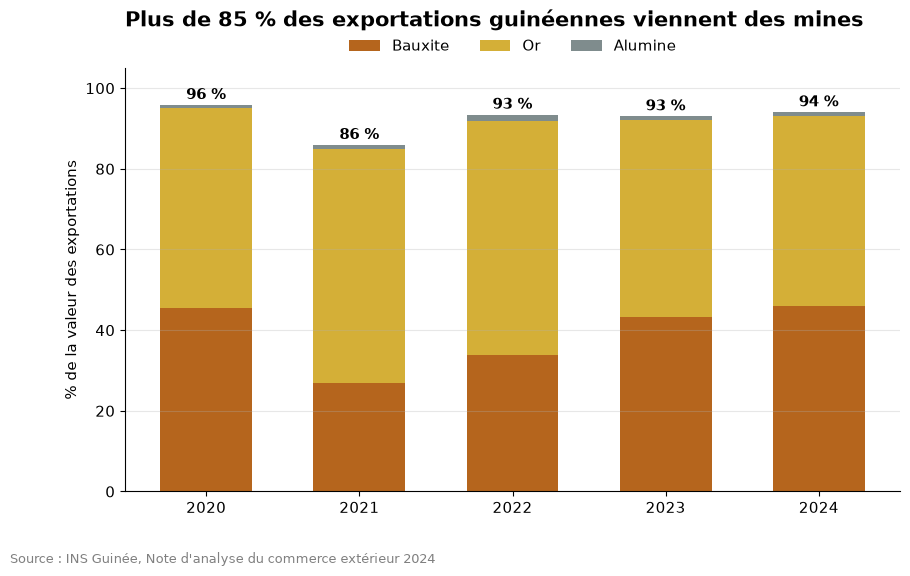

In [6]:
exports = duckdb.sql(f"""
    WITH e AS (
        SELECT annee,
               SUM(valeur) FILTER (WHERE indicateur = 'export_total')   AS total,
               SUM(valeur) FILTER (WHERE indicateur = 'export_bauxite') AS bauxite,
               SUM(valeur) FILTER (WHERE indicateur = 'export_or')      AS orr,
               SUM(valeur) FILTER (WHERE indicateur = 'export_alumine') AS alumine
        FROM {NAT}
        WHERE unite = 'milliards GNF'
        GROUP BY annee
    )
    SELECT annee,
           ROUND(100 * bauxite / total, 1) AS bauxite_pct,
           ROUND(100 * orr / total, 1)     AS or_pct,
           ROUND(100 * alumine / total, 1) AS alumine_pct,
           ROUND(100 * (bauxite + orr + alumine) / total, 1) AS mines_pct
    FROM e
    ORDER BY annee
""").df()
print(exports)

graphique_exportations(exports)

**Conclusion :** de 2020 à 2024, la bauxite, l'or et l'alumine représentent entre 86 % et 96 % des exportations de la Guinée (94 % en 2024). L'économie exportatrice repose presque entièrement sur deux produits : la bauxite et l'or.

## 4. Le boom de la bauxite (2019-2025)

   annee  millions_tonnes
0   2019        66.279526
1   2020        82.558146
2   2021        85.658219
3   2022       102.288468
4   2023       126.587724
5   2024       145.859987
6   2025       182.800000


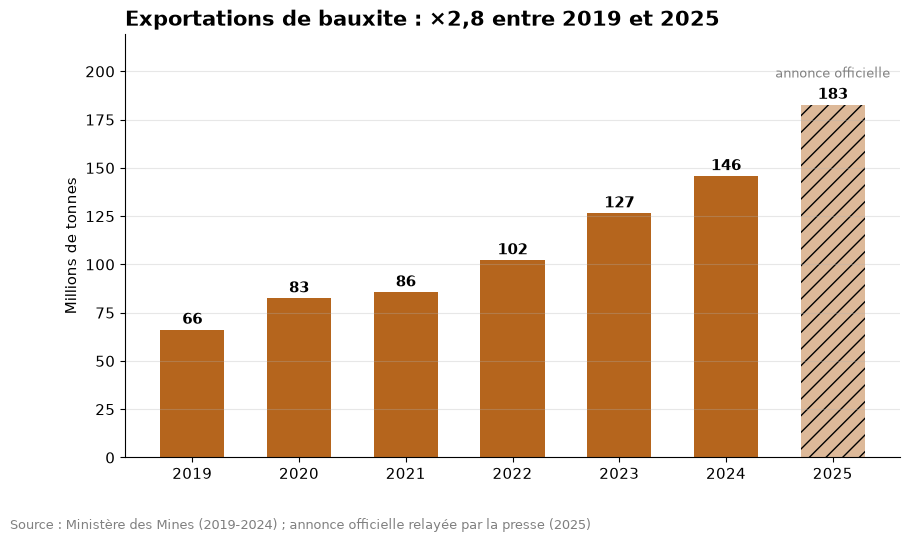

In [7]:
bauxite = duckdb.sql(f"""
    SELECT annee, valeur / 1e6 AS millions_tonnes
    FROM {NAT}
    WHERE indicateur = 'bauxite_exportation'
    ORDER BY annee
""").df()
print(bauxite)

graphique_bauxite(bauxite)

**Conclusion :** les exportations de bauxite sont passées d'environ 66 millions de tonnes en 2019 à environ 183 millions en 2025, soit près de 3 fois plus en six ans. Le chiffre 2025 vient d'une annonce officielle relayée par la presse et sera à confirmer avec le bulletin du ministère.

## 5. Le poids des mines dans le PIB

In [8]:
duckdb.sql(f"""
    SELECT annee, valeur AS part_extractif_pib_pct, source, note
    FROM {NAT}
    WHERE indicateur = 'part_extractif_pib'
    ORDER BY annee
""").show(max_width=200)

duckdb.sql(f"""
    SELECT annee, ROUND(valeur / 1e9, 1) AS pib_milliards_usd
    FROM {PIB}
    WHERE code_pays = 'GIN' AND annee IN (2000, 2010, 2019, 2023, 2025)
    ORDER BY annee
""").show()

┌───────┬────────────────────────┬───────────────────────────────────────────┬─────────────────────────────────────────────────────────────────────────────────┐
│ annee │ part_extractif_pib_pct │                  source                   │                                      note                                       │
│ int64 │         double         │                  varchar                  │                                     varchar                                     │
├───────┼────────────────────────┼───────────────────────────────────────────┼─────────────────────────────────────────────────────────────────────────────────┤
│  2019 │                   16.1 │ MMG Annuaire statistique 2023             │ ratio calcule: PIB extraction des minerais / PIB total, valeurs courantes       │
│  2020 │                   16.9 │ MMG Annuaire statistique 2023             │ ratio calcule: PIB extraction des minerais / PIB total, valeurs courantes       │
│  2021 │                   16.0 │

**Conclusion :** selon le Ministère des Mines, les industries extractives représentaient environ 16 % du PIB en 2019-2021, puis 10 à 12 % en 2022-2023. La baisse de la part ne veut pas dire que les mines reculent : le PIB total a fortement augmenté (13,4 milliards de dollars en 2019, 28,3 milliards en 2025 selon la Banque mondiale).

**Incohérence non résolue :** l'INS, cité par Bpifrance, donne 26 % pour 2024. Un passage de 10 % à 26 % en un an est peu crédible : les deux sources ne mesurent probablement pas la même chose. Je ne compare donc pas directement ces deux chiffres.

## Ce qu'il faut retenir

1. **La Guinée est le pays le plus dépendant des mines de la région :** 6,0 % du PIB en rente minière en moyenne sur 2000-2018, contre 4,1 % au Mali et moins de 1 % chez les trois autres voisins.
2. **Ses exportations reposent presque entièrement sur les mines :** bauxite, or et alumine font 94 % des exportations en 2024.
3. **Le boom de la bauxite est massif :** environ 66 Mt exportées en 2019 et environ 183 Mt en 2025, presque ×3.
4. **Les données ont des limites qu'il faut signaler :** une rente à 0 erronée en 2019-2021 dans la base de la Banque mondiale, un indicateur d'exportations qui exclut l'or, et des chiffres de part du PIB qui ne concordent pas entre sources.

**Prochaine étape :** la production et les paiements par entreprise (rapports ITIE), puis les pays clients (données miroir UN Comtrade).